# Task 3: unseen target sequences

Five frozen sequence-grouped splits per dataset; C0, sequence neighbours and learned factor ridge, trained separately on each cold-train partition.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir(), 'Run from the project root or notebooks directory'
sys.path.insert(0, str(ROOT))
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
from src.splits import load_splits
from src.cf import MatrixFactorization
from src.metrics import evaluate
from src.io import read_predictions
T = ROOT / 'results/tables'


In [2]:
display(pd.read_csv(T / 'task3_aggregate.csv'))
display(pd.read_csv(T / 'task3_coverage_cost.csv'))

,dataset,model,mse_mean,mse_std,mse_count,ci_global_mean,ci_global_std,ci_global_count,ci_per_ligand_mean,ci_per_ligand_std,...,hit1_count,hit5_mean,hit5_std,hit5_count,hit10_mean,hit10_std,hit10_count,mrr_mean,mrr_std,mrr_count
0,davis,factor_ridge,0.337409,0.042871,5,0.836450,0.008374,5,0.742904,0.024922,...,5,0.518360,0.070429,5,0.671836,0.092192,5,0.395342,0.084368,5
1,davis,ligand_mean,0.480029,0.071093,5,0.767476,0.007627,5,0.500000,0.000000,...,5,0.088453,0.001100,5,0.176764,0.001988,5,0.081646,0.000654,5
2,davis,sequence_neighbors,0.302536,0.039516,5,0.844811,0.012222,5,0.760390,0.017098,...,5,0.614260,0.093356,5,0.685195,0.087822,5,0.464532,0.088909,5
3,kiba,factor_ridge,0.323980,0.016150,5,0.756414,0.022212,5,0.641133,0.045614,...,5,0.667177,0.104161,5,0.833329,0.068173,5,0.537996,0.102214,5
4,kiba,ligand_mean,0.386760,0.035797,5,0.707669,0.022093,5,0.500000,0.000000,...,5,0.478350,0.040522,5,0.657432,0.045093,5,0.391831,0.060873,5
5,kiba,sequence_neighbors,0.306050,0.028115,5,0.769415,0.024419,5,0.648695,0.028803,...,5,0.726485,0.081729,5,0.892952,0.049452,5,0.557270,0.079399,5


,dataset,seed,primary_model,knn_test_fallback_fraction,unseen_ligand_test_pairs,cold_mf_seconds,whole_run_seconds
0,davis,2026,sequence_neighbors,0.000000,0,0.235993,5.442473
1,davis,2027,sequence_neighbors,0.000000,0,0.226182,4.137542
2,davis,2028,sequence_neighbors,0.000000,0,0.227661,4.180338
3,davis,2029,sequence_neighbors,0.000000,0,0.233793,4.120590
4,davis,2030,sequence_neighbors,0.000000,0,0.232039,4.098460
5,kiba,2026,factor_ridge,0.001450,0,0.496354,6.587316
6,kiba,2027,sequence_neighbors,0.003591,0,0.504167,5.872193
7,kiba,2028,sequence_neighbors,0.000923,0,0.496977,5.769607
8,kiba,2029,sequence_neighbors,0.001861,0,0.547684,5.795957
9,kiba,2030,sequence_neighbors,0.000943,0,0.479011,5.870200


Sample standard deviation is across target splits, not a confidence interval. Fixed 3-mer cosine is not alignment identity; similarity buckets are descriptive.

## DAVIS · seed 2026

,dataset,seed,model,bucket,pairs,targets,mse,ci
0,davis,2026,ligand_mean,<0.3,1496,22,0.374091,0.789785
1,davis,2026,sequence_neighbors,<0.3,1496,22,0.443582,0.762051
2,davis,2026,factor_ridge,<0.3,1496,22,0.346768,0.800640
3,davis,2026,ligand_mean,0.3–0.5,1088,16,0.511039,0.748071
4,davis,2026,sequence_neighbors,0.3–0.5,1088,16,0.270323,0.845160
5,davis,2026,factor_ridge,0.3–0.5,1088,16,0.349842,0.824700
6,davis,2026,ligand_mean,0.5–0.7,1020,15,0.294109,0.786713
7,davis,2026,sequence_neighbors,0.5–0.7,1020,15,0.100014,0.900661
8,davis,2026,factor_ridge,0.5–0.7,1020,15,0.150817,0.865051
9,davis,2026,ligand_mean,>=0.7,272,4,0.451248,0.669430


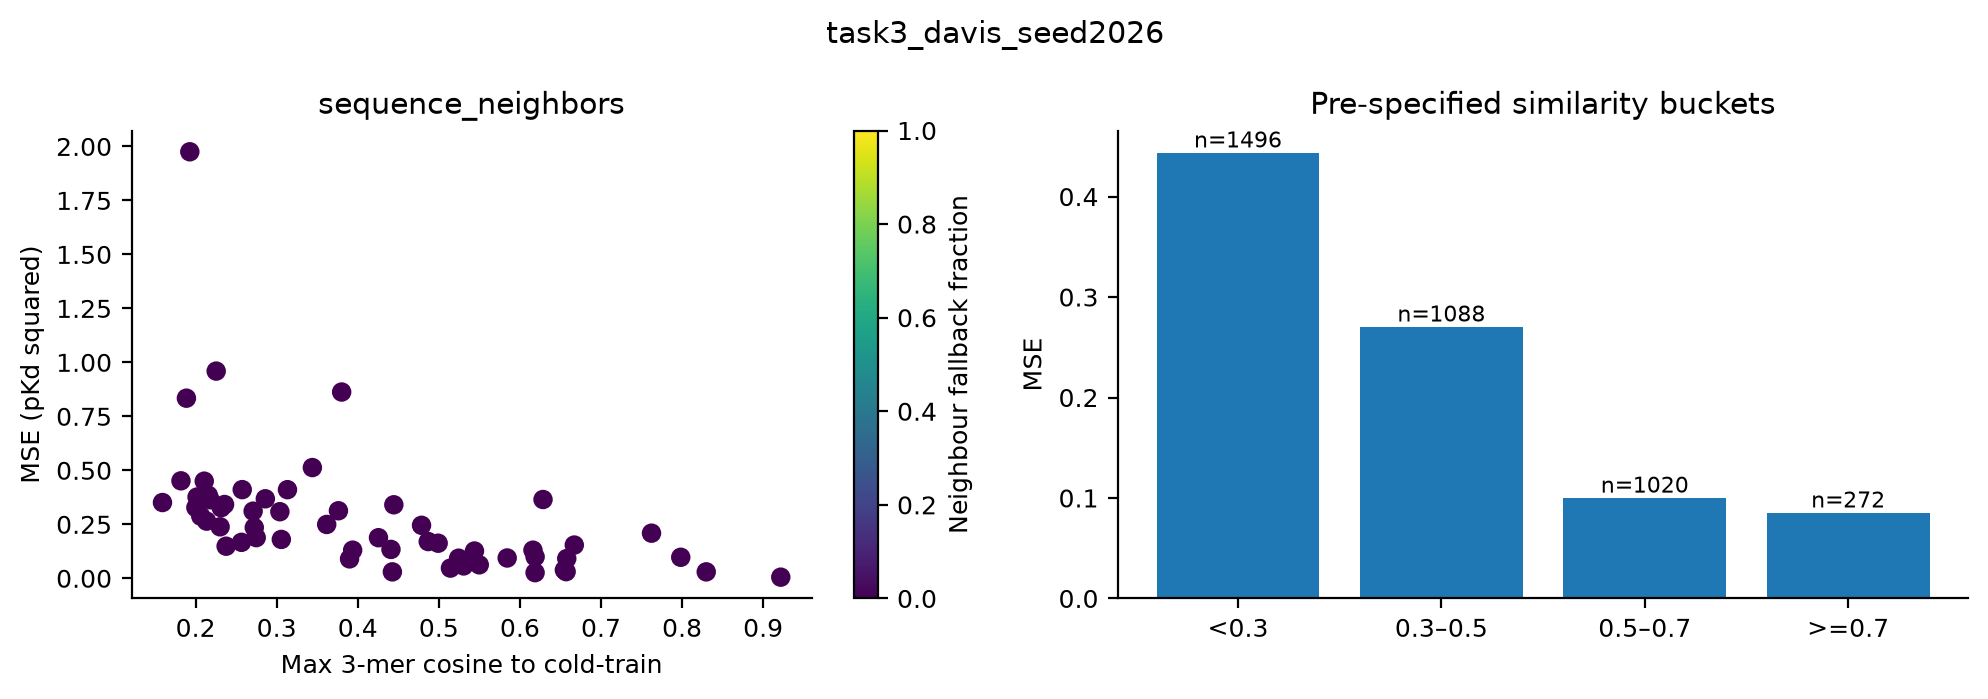

## KIBA · seed 2026

,dataset,seed,model,bucket,pairs,targets,mse,ci
0,kiba,2026,ligand_mean,<0.3,4104,9,0.346384,0.675968
1,kiba,2026,sequence_neighbors,<0.3,4104,9,0.359559,0.710897
2,kiba,2026,factor_ridge,<0.3,4104,9,0.339815,0.704858
3,kiba,2026,ligand_mean,0.3–0.5,8846,20,0.508746,0.717064
4,kiba,2026,sequence_neighbors,0.3–0.5,8846,20,0.327969,0.810914
5,kiba,2026,factor_ridge,0.3–0.5,8846,20,0.359478,0.799706
6,kiba,2026,ligand_mean,0.5–0.7,2781,5,0.325639,0.710622
7,kiba,2026,sequence_neighbors,0.5–0.7,2781,5,0.206410,0.756662
8,kiba,2026,factor_ridge,0.5–0.7,2781,5,0.204918,0.783442
9,kiba,2026,ligand_mean,>=0.7,129,1,1.107565,0.643511


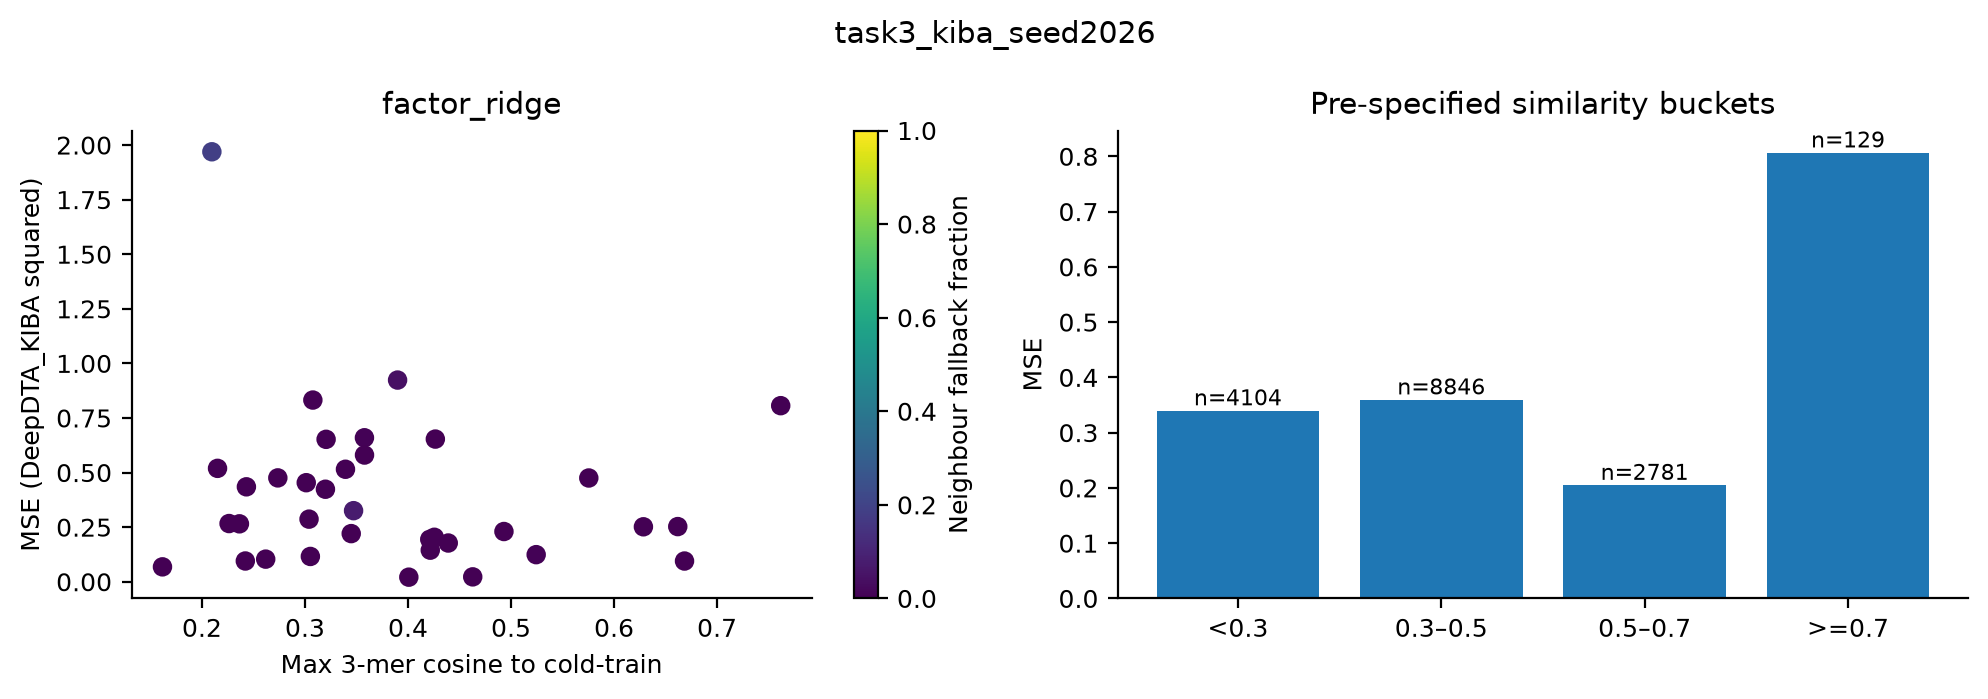

In [3]:
from src.cold import ColdTargetNeighbors, ColdFactorRidge
for dataset in ['davis','kiba']:
    for seed in range(2026,2031):
        _, parts, manifest = load_splits(dataset,'task3',seed)
        saved = read_predictions(ROOT / f'results/predictions/task3_{dataset}_seed{seed}_test.csv')
        neighbors = ColdTargetNeighbors.load(ROOT / f'saved_models/{dataset}_neighbors_seed{seed}.npz')
        ridge = ColdFactorRidge.load(ROOT / f'saved_models/{dataset}_ridge_seed{seed}.npz')
        assert set(parts['test'].sequence).isdisjoint(parts['train'].sequence)
        assert set(parts['test'].target_id).isdisjoint(neighbors.target_ids)
        assert neighbors.metadata['split_sha256'] == manifest['split_sha256']
        np.testing.assert_allclose(neighbors.predict(parts['test'])[0], saved.sequence_neighbors, atol=1e-12)
        np.testing.assert_allclose(ridge.predict(parts['test']), saved.factor_ridge, atol=1e-12)
    display(Markdown(f'## {dataset.upper()} · seed 2026'))
    display(pd.read_csv(T / f'task3_{dataset}_seed2026_similarity_buckets.csv'))
    display(Image(filename=str(ROOT / f'results/figures/task3_{dataset}_seed2026_similarity.png')))

Method, failure modes, all per-split metrics and assistance attribution: [Task 3 report notes](../results/task3_report_notes.md).